#Libraies

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import math
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

#Read the file

In [127]:
filepath = "/content/drive/MyDrive/ICT / ALL_CSV/Student_Depression_Dataset.csv"
df_std = pd.read_csv("/content/drive/MyDrive/ICT / ALL_CSV/Student_Depression_Dataset.csv")
df_std.head(3)

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes


#EDA

In [128]:
df_std.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [129]:
df_std.tail()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


In [130]:
df_std.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [131]:
num_cols = df_std.select_dtypes(include=['number']).columns
cat_cols = df_std.select_dtypes(include=['object']).columns

In [132]:
num_cols

Index(['Age', 'Current_semester', 'CGPA', 'Cost_without_study'], dtype='object')

In [133]:
cat_cols

Index(['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle', 'Health_condition', 'Home_division',
       'Depression'],
      dtype='object')

#Null Value Handling

In [134]:
df_std.isna().sum()

,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


In [135]:
cat_cols.isna().sum()

np.int64(0)

#Outliers Handling

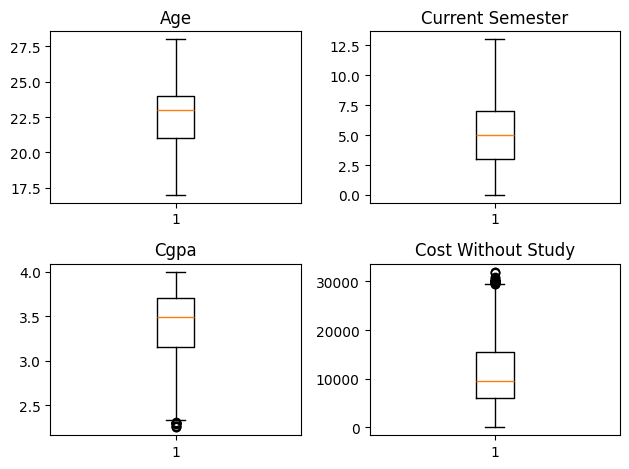

In [136]:
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    plt.boxplot(df_std[col])
    plt.title(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

In [137]:
Q1 = df_std[num_cols].quantile(0.25)
Q3 = df_std[num_cols].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

df_std[num_cols] =  df_std[num_cols].clip(lower=lower_limit, upper=upper_limit, axis=1)


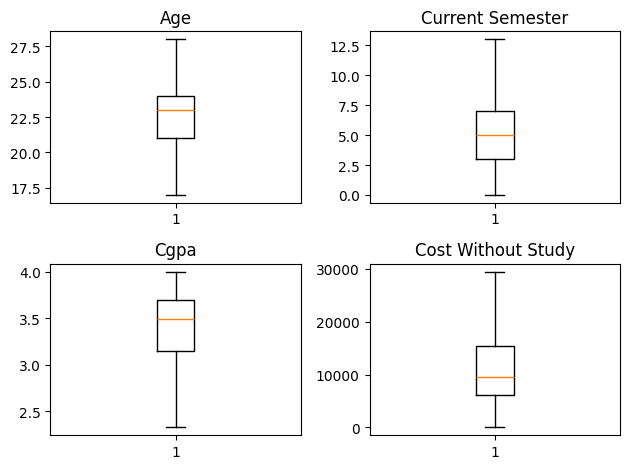

In [138]:
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    plt.boxplot(df_std[col])  # Fixed: pass df_bear[col] instead of df_bear
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()


#Duplicates Handling

In [139]:
df_std.duplicated().sum()

np.int64(0)

#Encoding

#Label Encoding

In [140]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
df_std['Depression'] = label_encoder.fit_transform(df_std['Depression'])
df_std.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113.0,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815.0,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450.0,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413.0,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693.0,Dhaka,1


In [141]:
df_std['Health_condition'].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

#Ordinal Encoding

In [142]:
from sklearn.preprocessing import OrdinalEncoder

encoder_health = OrdinalEncoder(
    categories=[['Normal','Good','Abnormal','Critical']]
)
df_std['Health_condition']=encoder_health.fit_transform(df_std[['Health_condition']])

In [143]:
df_std.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113.0,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815.0,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,2.0,15450.0,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,1.0,17413.0,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,2.0,16693.0,Dhaka,1


In [144]:
df_std['Family_background'].unique()

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [145]:
encoder_family = OrdinalEncoder(
    categories=[['Lower Middle class','Middle class','Rich class']]
)
df_std['Family_background']=encoder_family.fit_transform(df_std[['Family_background']])

In [146]:
df_std.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113.0,Chittagong,1
1,Male,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815.0,Chittagong,1
2,Male,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450.0,Dhaka,1
3,Male,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413.0,Dhaka,0
4,Female,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693.0,Dhaka,1


#OneHot Encoding





In [147]:
encoder = OneHotEncoder()

encoder_gender = encoder.fit_transform(df_std[["Gender"]])

encoder_gender= pd.DataFrame(
    encoder_gender.toarray(),
    columns=encoder.get_feature_names_out(['Gender']),
    index=df_std.index
)

In [148]:
encoder_gender.head()

,Gender_Female,Gender_Male
0,1.0,0.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,1.0,0.0


In [149]:
encoder = OneHotEncoder()

encoder_Relationship_status = encoder.fit_transform(df_std[["Relationship_status"]])

encoder_Relationship_status = pd.DataFrame(
    encoder_Relationship_status.toarray(),
    columns=encoder.get_feature_names_out(['Relationship_status']),
    index=df_std.index
)

In [150]:
encoder_Relationship_status.head()

,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single
0,0.0,0.0,1.0
1,0.0,0.0,1.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0


In [151]:
encoder = OneHotEncoder()

encoder_Marital_status = encoder.fit_transform(df_std[["Marital_status"]])

encoder_Marital_status = pd.DataFrame(
    encoder_Marital_status.toarray(),
    columns=encoder.get_feature_names_out(['Marital_status']),
    index=df_std.index
)

In [152]:
encoder_Marital_status.head()

,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried
0,0.0,0.0,1.0
1,0.0,0.0,1.0
2,0.0,0.0,1.0
3,0.0,0.0,1.0
4,0.0,0.0,1.0


In [153]:
encoder = OneHotEncoder()

encoder_Living_style = encoder.fit_transform(df_std[["Living_style"]])

encoder_Living_style = pd.DataFrame(
    encoder_Living_style.toarray(),
    columns=encoder.get_feature_names_out(['Living_style']),
    index=df_std.index
)

In [154]:
encoder_Living_style.head()

,Living_style_Bachelor,Living_style_Family
0,1.0,0.0
1,1.0,0.0
2,0.0,1.0
3,0.0,1.0
4,0.0,1.0


In [155]:

encoder = OneHotEncoder()

encoder_friend_circle = encoder.fit_transform(df_std[["friend_circle"]])

encoder_friend_circle = pd.DataFrame(
    encoder_friend_circle.toarray(),
    columns=encoder.get_feature_names_out(['friend_circle']),
    index=df_std.index
)

In [156]:
encoder_friend_circle.head()

,friend_circle_No,friend_circle_Yes
0,0.0,1.0
1,0.0,1.0
2,1.0,0.0
3,1.0,0.0
4,1.0,0.0


In [157]:

encoder = OneHotEncoder()

encoder_Home_division = encoder.fit_transform(df_std[["Home_division"]])

encoder_Home_division = pd.DataFrame(
    encoder_Home_division.toarray(),
    columns=encoder.get_feature_names_out(['Home_division']),
    index=df_std.index
)

In [158]:
encoder_Home_division.head()

,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


#

#Standard Scaling


In [159]:
df_std.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113.0,Chittagong,1
1,Male,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815.0,Chittagong,1
2,Male,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450.0,Dhaka,1
3,Male,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413.0,Dhaka,0
4,Female,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693.0,Dhaka,1


In [160]:
scaler = StandardScaler()
df_std[num_cols] = scaler.fit_transform(df_std[num_cols])
print(df_std.head())


   Gender       Age  Family_background Relationship_status Marital_status  \
0  Female -0.306105                1.0              Single      Unmarried   
1    Male -1.789232                1.0              Single      Unmarried   
2    Male  0.188270                1.0              Single      Unmarried   
3    Male -1.294857                1.0         Complicated      Unmarried   
4  Female -0.800481                1.0              Single      Unmarried   

  Living_style  Current_semester      CGPA friend_circle  Health_condition  \
0     Bachelor          1.007991  0.044499           Yes               3.0   
1     Bachelor         -1.319225  0.745317           Yes               2.0   
2       Family          1.007991 -0.344844            No               2.0   
3       Family         -1.319225  0.927010            No               1.0   
4       Family         -1.707095  1.524004            No               2.0   

   Cost_without_study Home_division  Depression  
0           -0.169